<a href="https://colab.research.google.com/github/Matheus-200/python_sis_26_2/blob/Matheus_Gabriel/aula_12/matheus_silva_aula12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Atividade Prática 01: Gestão de Ativos de TI e Auditoria de Logs

In [ ]:
# Etapa 1: Instalação, importação e criação da planilha de servidores
import openpyxl
from openpyxl.styles import PatternFill

# Criando o workbook e a aba de servidores
wb = openpyxl.Workbook()
ws_servidores = wb.active
ws_servidores.title = "Servidores"

# Adicionando o cabeçalho
cabecalho = ["Hostname", "IP", "Memória (GB)", "Uso de Disco (%)", "Status"]
ws_servidores.append(cabecalho)

# Dados fictícios para simulação
dados_servidores = [
    ["Servidor-01", "192.168.1.10", 16, 75, "Ativo"],
    ["Servidor-02", "192.168.1.11", 32, 85, "Ativo"], # Este vai precisar de atenção (>= 80%)
    ["Servidor-03", "192.168.1.12", 8, 45, "Ativo"],
    ["Servidor-04", "192.168.1.13", 64, 90, "Inativo"] # Este vai precisar de atenção (>= 80%)
]

for linha in dados_servidores:
    ws_servidores.append(linha)

print("Planilha de servidores inicializada com sucesso!")

Planilha de servidores inicializada com sucesso!


In [ ]:
# Etapa 2: Edição e Alerta de Uso de Disco >= 80%
# Definindo cor vermelha para o preenchimento de alerta
preenchimento_alerta = PatternFill(start_color="FFC7CE", end_color="FFC7CE", fill_type="solid")

# Iterando sobre as linhas de dados (pulando o cabeçalho)
for row in range(2, ws_servidores.max_row + 1):
    hostname = ws_servidores.cell(row=row, column=1).value
    uso_disco = ws_servidores.cell(row=row, column=4).value

    if uso_disco >= 80:
        print(f"⚠️ ALERTA: O servidor {hostname} está com {uso_disco}% de uso de disco e precisa de expansão!")
        # Colorindo a célula do Uso de Disco
        ws_servidores.cell(row=row, column=4).fill = preenchimento_alerta

⚠️ ALERTA: O servidor Servidor-02 está com 85% de uso de disco e precisa de expansão!
⚠️ ALERTA: O servidor Servidor-04 está com 90% de uso de disco e precisa de expansão!


In [ ]:
# Etapa 3: Abertura e Extração de Log (Garantindo que o arquivo exista)
# Criando o arquivo log.txt para teste
with open("log.txt", "w") as f:
    f.write("""2026-10-14 08:30:15 - INFO - Sistema inicializado com sucesso
2026-10-14 08:31:02 - INFO - Usuario 'admin' realizou login
2026-10-14 08:35:22 - AVISO - Tentativa de acesso com senha incorreta: usuario 'bat'
2026-10-14 08:35:40 - SUCESSO - Usuario 'bat' realizou login
2026-10-14 08:40:11 - ERRO - Falha ao conectar ao banco de dados: timeout
2026-10-14 08:42:00 - INFO - Conexao reestabelecida
""")

logs_extraidos = []
try:
    with open("log.txt", "r") as file:
        for linha in file:
            linha = linha.strip()
            if " - " in linha:
                partes = linha.split(" - ")
                data_hora = partes[0]
                tipo_evento = partes[1]
                mensagem = partes[2]

                logs_extraidos.append([data_hora, tipo_evento, mensagem])
                print(f"Evento Extraído: [{tipo_evento}] - {mensagem}")
except FileNotFoundError:
    print("Erro: O arquivo 'log.txt' não foi encontrado.")

Evento Extraído: [INFO] - Sistema inicializado com sucesso
Evento Extraído: [INFO] - Usuario 'admin' realizou login
Evento Extraído: [AVISO] - Tentativa de acesso com senha incorreta: usuario 'bat'
Evento Extraído: [SUCESSO] - Usuario 'bat' realizou login
Evento Extraído: [ERRO] - Falha ao conectar ao banco de dados: timeout
Evento Extraído: [INFO] - Conexao reestabelecida


In [ ]:
# Etapa 4: Salvando a auditoria de logs no Excel
ws_logs = wb.create_sheet(title="Auditoria Logs")
ws_logs.append(["Data/Hora", "Tipo de Evento", "Mensagem"])

for log in logs_extraidos:
    ws_logs.append(log)

wb.save("auditoria_servidores_logs.xlsx")
print("Arquivo 'auditoria_servidores_logs.xlsx' gerado e salvo com sucesso!")

Arquivo 'auditoria_servidores_logs.xlsx' gerado e salvo com sucesso!


### Atividade Prática 02: Coleta de Métricas de Hardware (psutil)

In [ ]:
# Etapas 1, 2, 3 e 4: Coleta de métricas e salvamento incremental no CSV
import psutil
import time

caminho_csv = "telemetria_sistema.csv"

# Gravando o cabeçalho explicitamente
with open(caminho_csv, "w") as f:
    f.write("Iteracao,Uso_CPU_Pct,Uso_RAM_Pct\n")

# Ciclo de 5 iterações de amostragem
for i in range(1, 6):
    cpu = psutil.cpu_percent(interval=None)
    ram = psutil.virtual_memory().percent

    # Salvando incrementalmente no modo 'a'
    with open(caminho_csv, "a") as f:
        f.write(f"{i},{cpu},{ram}\n")

    print(f"Iteração {i}/5 salva: CPU: {cpu}% | RAM: {ram}%")
    time.sleep(1)

Iteração 1/5 salva: CPU: 32.4% | RAM: 9.9%
Iteração 2/5 salva: CPU: 3.0% | RAM: 9.9%
Iteração 3/5 salva: CPU: 4.5% | RAM: 9.9%
Iteração 4/5 salva: CPU: 4.5% | RAM: 9.9%
Iteração 5/5 salva: CPU: 3.0% | RAM: 9.9%


### Atividade Prática 03: Análise e Visualização dos Dados de Telemetria

--- Resumo Descritivo das Métricas ---
Média de Uso da CPU: 9.48%
Média de Uso da RAM: 9.90%
-------------------------------------


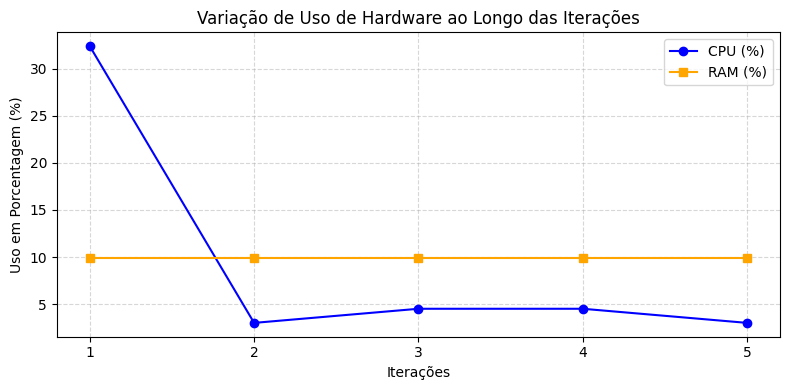

In [ ]:
# Etapas 1, 2 e 3: Leitura com Pandas, cálculo de médias e plotagem de gráficos
import pandas as pd
import matplotlib.pyplot as plt

# Ingestão do arquivo CSV
df = pd.read_csv("telemetria_sistema.csv")

# Cálculo das médias aritméticas
media_cpu = df["Uso_CPU_Pct"].mean()
media_ram = df["Uso_RAM_Pct"].mean()

print("--- Resumo Descritivo das Métricas ---")
print(f"Média de Uso da CPU: {media_cpu:.2f}%")
print(f"Média de Uso da RAM: {media_ram:.2f}%")
print("-------------------------------------")

# Plotagem do gráfico de linha
plt.figure(figsize=(8, 4))
plt.plot(df["Iteracao"], df["Uso_CPU_Pct"], marker='o', label='CPU (%)', color='blue')
plt.plot(df["Iteracao"], df["Uso_RAM_Pct"], marker='s', label='RAM (%)', color='orange')

plt.title("Variação de Uso de Hardware ao Longo das Iterações")
plt.xlabel("Iterações")
plt.ylabel("Uso em Porcentagem (%)")
plt.xticks(df["Iteracao"])
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()